In [1]:
# Cell 1: Import Libraries and Configure Environment
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, roc_auc_score, confusion_matrix, roc_curve, auc, ConfusionMatrixDisplay)
from sklearn.ensemble import RandomForestClassifier
import warnings
import time
import os
warnings.filterwarnings('ignore')

# Set visualization style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
np.random.seed(42)

print("="*100)
print("RANDOM FOREST HYPERPARAMETER TUNING - COMPLETE ANALYSIS")
print("="*100)
print("\n✓ All libraries imported successfully")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

RANDOM FOREST HYPERPARAMETER TUNING - COMPLETE ANALYSIS

✓ All libraries imported successfully
NumPy version: 2.2.6
Pandas version: 2.3.3


In [2]:
# Cell 2: Load Split Datasets (Train/Validation/Test)

print("\n" + "="*100)
print("LOADING SPLIT DATASETS (TRAIN/VALIDATION/TEST)")
print("="*100)

# Load split datasets
df_train = pd.read_csv('final_ml_dataset_train.csv')
df_val = pd.read_csv('final_ml_dataset_validation.csv')
df_test = pd.read_csv('final_ml_dataset_test.csv')

print(f"\n✓ Loaded final_ml_dataset_train.csv: {df_train.shape}")
print(f"✓ Loaded final_ml_dataset_validation.csv: {df_val.shape}")
print(f"✓ Loaded final_ml_dataset_test.csv: {df_test.shape}")

# Load complete dataset for reference
df_complete = pd.read_csv('ml_dataset_complete_with_finger_bits.csv')
df_descriptors = pd.read_csv('ml_Descriptor_features_complete.csv')

print(f"\n✓ Loaded ml_dataset_complete_with_finger_bits.csv: {df_complete.shape}")
print(f"✓ Loaded ml_Descriptor_features_complete.csv: {df_descriptors.shape}")

# Extract target variables
y_train = df_train['Activity'].values
y_val = df_val['Activity'].values
y_test = df_test['Activity'].values

print(f"\n{'Data Split Summary':^100}")
print(f"{'-'*100}")
print(f"Training set:   {len(y_train):4d} samples (Active: {np.sum(y_train):3d}, Inactive: {len(y_train)-np.sum(y_train):3d})")
print(f"Validation set: {len(y_val):4d} samples (Active: {np.sum(y_val):3d}, Inactive: {len(y_val)-np.sum(y_val):3d})")
print(f"Test set:       {len(y_test):4d} samples (Active: {np.sum(y_test):3d}, Inactive: {len(y_test)-np.sum(y_test):3d})")
print(f"Total:          {len(y_train) + len(y_val) + len(y_test):4d} samples")


LOADING SPLIT DATASETS (TRAIN/VALIDATION/TEST)

✓ Loaded final_ml_dataset_train.csv: (1188, 4516)
✓ Loaded final_ml_dataset_validation.csv: (255, 4516)
✓ Loaded final_ml_dataset_test.csv: (255, 4516)

✓ Loaded final_ml_dataset_train.csv: (1188, 4516)
✓ Loaded final_ml_dataset_validation.csv: (255, 4516)
✓ Loaded final_ml_dataset_test.csv: (255, 4516)

✓ Loaded ml_dataset_complete_with_finger_bits.csv: (1698, 4516)
✓ Loaded ml_Descriptor_features_complete.csv: (1698, 251)

                                         Data Split Summary                                         
----------------------------------------------------------------------------------------------------
Training set:   1188 samples (Active: 440, Inactive: 748)
Validation set:  255 samples (Active:  94, Inactive: 161)
Test set:        255 samples (Active:  95, Inactive: 160)
Total:          1698 samples

✓ Loaded ml_dataset_complete_with_finger_bits.csv: (1698, 4516)
✓ Loaded ml_Descriptor_features_complete.csv: (1698,

In [4]:
# Cell 3: Extract and Prepare Four Feature Sets from Split Datasets

print("\n" + "="*100)
print("PREPARING FOUR FEATURE SETS FROM SPLIT DATASETS")
print("="*100)

# Identify feature columns in each set
# Split datasets have "Scaled_" prefix for descriptors, so we need to filter appropriately
scaled_descriptor_cols = [col for col in df_train.columns if col.startswith('Scaled_') and not any(
    x in col for x in ['MACCS', 'RDKit', 'Morgan'])]

maccs_cols = [col for col in df_train.columns if 'MACCS_bit' in col]
rdkit_cols = [col for col in df_train.columns if 'RDKit_bit' in col]
morgan_cols = [col for col in df_train.columns if 'Morgan_bit' in col]

print(f"\nFeature column identification:") 
print(f"  217 Descriptors (Scaled): {len(scaled_descriptor_cols)} features")
print(f"  MACCS_167: {len(maccs_cols)} features")
print(f"  RDKit_2048: {len(rdkit_cols)} features")
print(f"  Morgan_2048: {len(morgan_cols)} features")

# Extract training set features
X_train_descriptors = df_train[scaled_descriptor_cols].values
X_train_maccs = df_train[maccs_cols].values
X_train_rdkit = df_train[rdkit_cols].values
X_train_morgan = df_train[morgan_cols].values

# Extract validation set features
X_val_descriptors = df_val[scaled_descriptor_cols].values
X_val_maccs = df_val[maccs_cols].values
X_val_rdkit = df_val[rdkit_cols].values
X_val_morgan = df_val[morgan_cols].values

# Extract test set features
X_test_descriptors = df_test[scaled_descriptor_cols].values
X_test_maccs = df_test[maccs_cols].values
X_test_rdkit = df_test[rdkit_cols].values
X_test_morgan = df_test[morgan_cols].values

# Features are already scaled in the split datasets, so we don't need to scale again
# But we'll verify they're numeric
print(f"\nFeature verification:") 
print(f"  Train descriptors dtype: {X_train_descriptors.dtype}") 
print(f"  Train MACCS dtype: {X_train_maccs.dtype}")
print(f"  Train RDKit dtype: {X_train_rdkit.dtype}")
print(f"  Train Morgan dtype: {X_train_morgan.dtype}")

# Store all feature sets
feature_sets = {
    '217_Descriptors': {
        'name': '217 Descriptors (Scaled)',
        'X_train': X_train_descriptors,
        'X_val': X_val_descriptors,
        'X_test': X_test_descriptors,
        'n_features': X_train_descriptors.shape[1]
    },
    'MACCS_167': {
        'name': 'MACCS_167',
        'X_train': X_train_maccs,
        'X_val': X_val_maccs,
        'X_test': X_test_maccs,
        'n_features': X_train_maccs.shape[1]
    },
    'RDKit_2048': {
        'name': 'RDKit_2048',
        'X_train': X_train_rdkit,
        'X_val': X_val_rdkit,
        'X_test': X_test_rdkit,
        'n_features': X_train_rdkit.shape[1]
    },
    'Morgan_2048': {
        'name': 'Morgan_2048',
        'X_train': X_train_morgan,
        'X_val': X_val_morgan,
        'X_test': X_test_morgan,
        'n_features': X_train_morgan.shape[1]
    }
}

print(f"\n{'Feature Sets Prepared':^100}")
print(f"{'-'*100}")
for key, info in feature_sets.items():
    print(f"{info['name']:25s} - Train: {info['X_train'].shape} | Val: {info['X_val'].shape} | Test: {info['X_test'].shape}")

print(f"\n✓ All feature sets extracted successfully")


PREPARING FOUR FEATURE SETS FROM SPLIT DATASETS

Feature column identification:
  217 Descriptors (Scaled): 240 features
  MACCS_167: 169 features
  RDKit_2048: 2050 features
  Morgan_2048: 2050 features

Feature verification:
  Train descriptors dtype: float64
  Train MACCS dtype: float64
  Train RDKit dtype: float64
  Train Morgan dtype: float64

                                       Feature Sets Prepared                                        
----------------------------------------------------------------------------------------------------
217 Descriptors (Scaled)  - Train: (1188, 240) | Val: (255, 240) | Test: (255, 240)
MACCS_167                 - Train: (1188, 169) | Val: (255, 169) | Test: (255, 169)
RDKit_2048                - Train: (1188, 2050) | Val: (255, 2050) | Test: (255, 2050)
Morgan_2048               - Train: (1188, 2050) | Val: (255, 2050) | Test: (255, 2050)

✓ All feature sets extracted successfully


In [5]:
# Cell 4: Define Hyperparameter Grid

print("\n" + "="*100)
print("DEFINING HYPERPARAMETER GRID FOR RANDOM FOREST")
print("="*100)

param_grid = {
    'n_estimators': [200, 300, 400, 500, 600],
    'max_depth': [10, 20, 30, 42],
    'min_samples_split': [2, 5, 10]
}

print(f"\nHyperparameter Grid:")
for param, values in param_grid.items():
    print(f"  {param:20s}: {values}")

# Calculate total combinations
n_combinations = 1
for values in param_grid.values():
    n_combinations *= len(values)

print(f"\nGrid Search Configuration:")
print(f"  Total parameter combinations: {n_combinations}")
print(f"  Total grid searches: {n_combinations * len(feature_sets)} (across {len(feature_sets)} feature sets)")
print(f"  Total CV iterations: {n_combinations * len(feature_sets) * 5} (with 5-fold CV)")

# Cross-validation strategy
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(f"\nCross-Validation Strategy:")
print(f"  Method: StratifiedKFold")
print(f"  Splits: {cv_strategy.get_n_splits()}")
print(f"  Random State: 42")
print(f"  Shuffle: True")

print(f"\n✓ Hyperparameter grid defined successfully")


DEFINING HYPERPARAMETER GRID FOR RANDOM FOREST

Hyperparameter Grid:
  n_estimators        : [200, 300, 400, 500, 600]
  max_depth           : [10, 20, 30, 42]
  min_samples_split   : [2, 5, 10]

Grid Search Configuration:
  Total parameter combinations: 60
  Total grid searches: 240 (across 4 feature sets)
  Total CV iterations: 1200 (with 5-fold CV)

Cross-Validation Strategy:
  Method: StratifiedKFold
  Splits: 5
  Random State: 42
  Shuffle: True

✓ Hyperparameter grid defined successfully


In [6]:
# Cell 5: Execute Hyperparameter Tuning with 5-Fold CV on Training Set

print("\n" + "="*100)
print("EXECUTING HYPERPARAMETER TUNING (5-FOLD CV ON TRAINING SET)")
print("="*100)

tuning_results = {}

for feature_key, feature_info in feature_sets.items():
    print(f"\n{'-'*100}")
    print(f"Processing: {feature_info['name']}")
    print(f"{'-'*100}")
    
    X_train = feature_info['X_train']
    
    # Initialize base Random Forest model
    rf_model = RandomForestClassifier(
        random_state=42,
        n_jobs=-1,
        verbose=0
    )
    
    print(f"Training set shape: {X_train.shape}")
    print(f"Starting GridSearchCV with {n_combinations} combinations...")
    
    start_time = time.time()
    
    # Perform GridSearchCV
    grid_search = GridSearchCV(
        estimator=rf_model,
        param_grid=param_grid,
        cv=cv_strategy,
        scoring='roc_auc',
        n_jobs=-1,
        verbose=0
    )
    
    # Fit on training set only
    grid_search.fit(X_train, y_train)
    
    elapsed = time.time() - start_time
    
    # Extract results
    cv_results = pd.DataFrame(grid_search.cv_results_)
    
    # Store results
    tuning_results[feature_key] = {
        'name': feature_info['name'],
        'best_params': grid_search.best_params_,
        'best_score_cv': grid_search.best_score_,
        'best_model': grid_search.best_estimator_,
        'grid_search': grid_search,
        'cv_results': cv_results,
        'elapsed_time': elapsed,
        'feature_info': feature_info
    }
    
    # Print summary
    print(f"\n✓ Tuning completed in {elapsed:.2f} seconds")
    print(f"\nBest Parameters:")
    for param, value in grid_search.best_params_.items():
        print(f"  {param:20s}: {value}")
    
    print(f"\nBest Cross-Validation Score (ROC-AUC): {grid_search.best_score_:.6f}")

print(f"\n{'='*100}")
print(f"✓ HYPERPARAMETER TUNING COMPLETED FOR ALL FEATURE SETS")
print(f"{'='*100}")
print(f"\nFeature sets tuned: {list(tuning_results.keys())}")
total_time = sum([results['elapsed_time'] for results in tuning_results.values()])
print(f"Total execution time: {total_time:.2f} seconds")


EXECUTING HYPERPARAMETER TUNING (5-FOLD CV ON TRAINING SET)

----------------------------------------------------------------------------------------------------
Processing: 217 Descriptors (Scaled)
----------------------------------------------------------------------------------------------------
Training set shape: (1188, 240)
Starting GridSearchCV with 60 combinations...

✓ Tuning completed in 43.20 seconds

Best Parameters:
  max_depth           : 20
  min_samples_split   : 2
  n_estimators        : 500

Best Cross-Validation Score (ROC-AUC): 0.853296

----------------------------------------------------------------------------------------------------
Processing: MACCS_167
----------------------------------------------------------------------------------------------------
Training set shape: (1188, 169)
Starting GridSearchCV with 60 combinations...

✓ Tuning completed in 43.20 seconds

Best Parameters:
  max_depth           : 20
  min_samples_split   : 2
  n_estimators        : 5

In [7]:
# Cell 6: Evaluate Best Models on Training, Validation, and Test Sets

print("\n" + "="*100)
print("EVALUATING BEST MODELS ON TRAINING, VALIDATION, AND TEST SETS")
print("="*100)

evaluation_results = {}

for feature_key, tuning_result in tuning_results.items():
    print(f"\n{'='*100}")
    print(f"Feature Set: {tuning_result['name']}")
    print(f"{'='*100}")
    
    best_model = tuning_result['best_model']
    feature_info = tuning_result['feature_info']
    
    X_train = feature_info['X_train']
    X_val = feature_info['X_val']
    X_test = feature_info['X_test']
    
    # Predictions on all sets
    y_train_pred = best_model.predict(X_train)
    y_train_proba = best_model.predict_proba(X_train)[:, 1]
    
    y_val_pred = best_model.predict(X_val)
    y_val_proba = best_model.predict_proba(X_val)[:, 1]
    
    y_test_pred = best_model.predict(X_test)
    y_test_proba = best_model.predict_proba(X_test)[:, 1]
    
    # Calculate metrics for training set
    train_metrics = {
        'accuracy': accuracy_score(y_train, y_train_pred),
        'precision': precision_score(y_train, y_train_pred),
        'recall': recall_score(y_train, y_train_pred),
        'f1': f1_score(y_train, y_train_pred),
        'roc_auc': roc_auc_score(y_train, y_train_proba)
    }
    
    # Calculate metrics for validation set
    val_metrics = {
        'accuracy': accuracy_score(y_val, y_val_pred),
        'precision': precision_score(y_val, y_val_pred),
        'recall': recall_score(y_val, y_val_pred),
        'f1': f1_score(y_val, y_val_pred),
        'roc_auc': roc_auc_score(y_val, y_val_proba)
    }
    
    # Calculate metrics for test set
    test_metrics = {
        'accuracy': accuracy_score(y_test, y_test_pred),
        'precision': precision_score(y_test, y_test_pred),
        'recall': recall_score(y_test, y_test_pred),
        'f1': f1_score(y_test, y_test_pred),
        'roc_auc': roc_auc_score(y_test, y_test_proba)
    }
    
    # Confusion matrix for test set
    cm_test = confusion_matrix(y_test, y_test_pred)
    tn, fp, fn, tp = cm_test.ravel()
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    # Print results
    print(f"\n{'-'*100}")
    print(f"TRAINING SET METRICS:")
    print(f"{'-'*100}")
    print(f"  Accuracy:  {train_metrics['accuracy']:.6f}")
    print(f"  Precision: {train_metrics['precision']:.6f}")
    print(f"  Recall:    {train_metrics['recall']:.6f}")
    print(f"  F1-Score:  {train_metrics['f1']:.6f}")
    print(f"  ROC-AUC:   {train_metrics['roc_auc']:.6f}")
    
    print(f"\n{'-'*100}")
    print(f"VALIDATION SET METRICS:")
    print(f"{'-'*100}")
    print(f"  Accuracy:  {val_metrics['accuracy']:.6f}")
    print(f"  Precision: {val_metrics['precision']:.6f}")
    print(f"  Recall:    {val_metrics['recall']:.6f}")
    print(f"  F1-Score:  {val_metrics['f1']:.6f}")
    print(f"  ROC-AUC:   {val_metrics['roc_auc']:.6f}")
    
    print(f"\n{'-'*100}")
    print(f"TEST SET METRICS (FINAL EVALUATION):")
    print(f"{'-'*100}")
    print(f"  Accuracy:   {test_metrics['accuracy']:.6f}")
    print(f"  Precision:  {test_metrics['precision']:.6f}")
    print(f"  Recall:     {test_metrics['recall']:.6f}")
    print(f"  F1-Score:   {test_metrics['f1']:.6f}")
    print(f"  ROC-AUC:    {test_metrics['roc_auc']:.6f}")
    print(f"  Specificity: {specificity:.6f}")
    print(f"  Sensitivity: {sensitivity:.6f}")
    
    print(f"\n{'-'*100}")
    print(f"TEST SET CONFUSION MATRIX:")
    print(f"{'-'*100}")
    print(f"                Predicted")
    print(f"                Negative  Positive")
    print(f"Actual Negative {tn:6d}    {fp:6d}")
    print(f"       Positive {fn:6d}    {tp:6d}")
    
    # Store evaluation results
    evaluation_results[feature_key] = {
        'name': tuning_result['name'],
        'best_params': tuning_result['best_params'],
        'best_model': best_model,
        'train_metrics': train_metrics,
        'val_metrics': val_metrics,
        'test_metrics': test_metrics,
        'confusion_matrix': cm_test,
        'y_test_pred': y_test_pred,
        'y_test_proba': y_test_proba,
        'sensitivity': sensitivity,
        'specificity': specificity
    }

print(f"\n{'='*100}")
print(f"✓ Evaluation completed for all feature sets")
print(f"{'='*100}")


EVALUATING BEST MODELS ON TRAINING, VALIDATION, AND TEST SETS

Feature Set: 217 Descriptors (Scaled)

----------------------------------------------------------------------------------------------------
TRAINING SET METRICS:
----------------------------------------------------------------------------------------------------
  Accuracy:  0.999158
  Precision: 1.000000
  Recall:    0.997727
  F1-Score:  0.998862
  ROC-AUC:   0.999998

----------------------------------------------------------------------------------------------------
VALIDATION SET METRICS:
----------------------------------------------------------------------------------------------------
  Accuracy:  0.815686
  Precision: 0.790123
  Recall:    0.680851
  F1-Score:  0.731429
  ROC-AUC:   0.880831

----------------------------------------------------------------------------------------------------
TEST SET METRICS (FINAL EVALUATION):
---------------------------------------------------------------------------------------

In [8]:
# Cell 7: Create Comprehensive Summary Tables

print("\n" + "="*100)
print("CREATING COMPREHENSIVE SUMMARY TABLES")
print("="*100)

# Overall summary
summary_data = []
train_metrics_list = []
val_metrics_list = []
test_metrics_list = []
cm_analysis_list = []

for feature_key, results in evaluation_results.items():
    # Overall summary
    summary_data.append({
        'Feature_Set': results['name'],
        'n_estimators': results['best_params']['n_estimators'],
        'max_depth': results['best_params']['max_depth'],
        'min_samples_split': results['best_params']['min_samples_split'],
        'Train_Accuracy': results['train_metrics']['accuracy'],
        'Val_Accuracy': results['val_metrics']['accuracy'],
        'Test_Accuracy': results['test_metrics']['accuracy'],
        'Test_Precision': results['test_metrics']['precision'],
        'Test_Recall': results['test_metrics']['recall'],
        'Test_F1': results['test_metrics']['f1'],
        'Test_ROC_AUC': results['test_metrics']['roc_auc']
    })
    
    # Training metrics
    train_metrics_list.append({
        'Feature_Set': results['name'],
        'Accuracy': results['train_metrics']['accuracy'],
        'Precision': results['train_metrics']['precision'],
        'Recall': results['train_metrics']['recall'],
        'F1_Score': results['train_metrics']['f1'],
        'ROC_AUC': results['train_metrics']['roc_auc']
    })
    
    # Validation metrics
    val_metrics_list.append({
        'Feature_Set': results['name'],
        'Accuracy': results['val_metrics']['accuracy'],
        'Precision': results['val_metrics']['precision'],
        'Recall': results['val_metrics']['recall'],
        'F1_Score': results['val_metrics']['f1'],
        'ROC_AUC': results['val_metrics']['roc_auc']
    })
    
    # Test metrics
    test_metrics_list.append({
        'Feature_Set': results['name'],
        'Accuracy': results['test_metrics']['accuracy'],
        'Precision': results['test_metrics']['precision'],
        'Recall': results['test_metrics']['recall'],
        'F1_Score': results['test_metrics']['f1'],
        'ROC_AUC': results['test_metrics']['roc_auc'],
        'Specificity': results['specificity'],
        'Sensitivity': results['sensitivity']
    })
    
    # Confusion matrix analysis
    cm = results['confusion_matrix']
    tn, fp, fn, tp = cm.ravel()
    cm_analysis_list.append({
        'Feature_Set': results['name'],
        'True_Negatives': tn,
        'False_Positives': fp,
        'False_Negatives': fn,
        'True_Positives': tp,
        'Sensitivity': results['sensitivity'],
        'Specificity': results['specificity']
    })

# Create DataFrames
summary_df = pd.DataFrame(summary_data)
train_df = pd.DataFrame(train_metrics_list)
val_df = pd.DataFrame(val_metrics_list)
test_df = pd.DataFrame(test_metrics_list)
cm_df = pd.DataFrame(cm_analysis_list)

# Print tables
print("\n" + "="*100)
print("1. OVERALL SUMMARY - BEST HYPERPARAMETERS AND TEST PERFORMANCE")
print("="*100)
print(summary_df.to_string(index=False))

print("\n" + "="*100)
print("2. TRAINING SET METRICS")
print("="*100)
print(train_df.to_string(index=False))

print("\n" + "="*100)
print("3. VALIDATION SET METRICS")
print("="*100)
print(val_df.to_string(index=False))

print("\n" + "="*100)
print("4. TEST SET METRICS (FINAL EVALUATION)")
print("="*100)
print(test_df.to_string(index=False))

print("\n" + "="*100)
print("5. CONFUSION MATRIX ANALYSIS (TEST SET)")
print("="*100)
print(cm_df.to_string(index=False))


CREATING COMPREHENSIVE SUMMARY TABLES

1. OVERALL SUMMARY - BEST HYPERPARAMETERS AND TEST PERFORMANCE
             Feature_Set  n_estimators  max_depth  min_samples_split  Train_Accuracy  Val_Accuracy  Test_Accuracy  Test_Precision  Test_Recall  Test_F1  Test_ROC_AUC
217 Descriptors (Scaled)           500         20                  2        0.999158      0.815686       0.811765        0.770115     0.705263 0.736264      0.860461
               MACCS_167           500         10                  2        0.851852      0.807843       0.737255        0.670732     0.578947 0.621469      0.799934
              RDKit_2048           500         30                  5        0.976431      0.866667       0.800000        0.739130     0.715789 0.727273      0.874375
             Morgan_2048           500         42                  2        0.997475      0.835294       0.803922        0.747253     0.715789 0.731183      0.882664

2. TRAINING SET METRICS
             Feature_Set  Accuracy  Precis

In [9]:
# Cell 8: Export Results to CSV

print("\n" + "="*100)
print("EXPORTING RESULTS TO CSV FILES")
print("="*100)

output_dir = r'c:\Users\omen\OneDrive\Documents\NMDAR_ML'
os.makedirs(output_dir, exist_ok=True)

# Export all summary tables
files_saved = []

# 1. Overall summary
summary_csv = os.path.join(output_dir, 'RF_overall_summary.csv')
summary_df.to_csv(summary_csv, index=False)
files_saved.append(f"✓ Saved: RF_overall_summary.csv")

# 2. Training metrics
train_csv = os.path.join(output_dir, 'RF_training_metrics.csv')
train_df.to_csv(train_csv, index=False)
files_saved.append(f"✓ Saved: RF_training_metrics.csv")

# 3. Validation metrics
val_csv = os.path.join(output_dir, 'RF_validation_metrics.csv')
val_df.to_csv(val_csv, index=False)
files_saved.append(f"✓ Saved: RF_validation_metrics.csv")

# 4. Test metrics
test_csv = os.path.join(output_dir, 'RF_test_metrics.csv')
test_df.to_csv(test_csv, index=False)
files_saved.append(f"✓ Saved: RF_test_metrics.csv")

# 5. Confusion matrix analysis
cm_csv = os.path.join(output_dir, 'RF_confusion_matrix_analysis.csv')
cm_df.to_csv(cm_csv, index=False)
files_saved.append(f"✓ Saved: RF_confusion_matrix_analysis.csv")

# 6. Export hyperparameter tuning results for each feature set
for feature_key, tuning_result in tuning_results.items():
    cv_results = tuning_result['cv_results']
    
    export_cols = ['param_n_estimators', 'param_max_depth', 'param_min_samples_split',
                   'mean_test_score', 'std_test_score', 'rank_test_score']
    
    export_df = cv_results[export_cols].copy()
    export_df.columns = ['n_estimators', 'max_depth', 'min_samples_split',
                         'cv_score_mean', 'cv_score_std', 'rank']
    export_df = export_df.sort_values('rank')
    
    hp_csv = os.path.join(output_dir, f"RF_hyperparameters_{feature_key}.csv")
    export_df.to_csv(hp_csv, index=False)
    files_saved.append(f"✓ Saved: RF_hyperparameters_{feature_key}.csv")

print("\n" + "="*100)
print("CSV FILES SAVED")
print("="*100)
for file_msg in files_saved:
    print(file_msg)

print(f"\n✓ All results exported successfully to {output_dir}")


EXPORTING RESULTS TO CSV FILES

CSV FILES SAVED
✓ Saved: RF_overall_summary.csv
✓ Saved: RF_training_metrics.csv
✓ Saved: RF_validation_metrics.csv
✓ Saved: RF_test_metrics.csv
✓ Saved: RF_confusion_matrix_analysis.csv
✓ Saved: RF_hyperparameters_217_Descriptors.csv
✓ Saved: RF_hyperparameters_MACCS_167.csv
✓ Saved: RF_hyperparameters_RDKit_2048.csv
✓ Saved: RF_hyperparameters_Morgan_2048.csv

✓ All results exported successfully to c:\Users\omen\OneDrive\Documents\NMDAR_ML


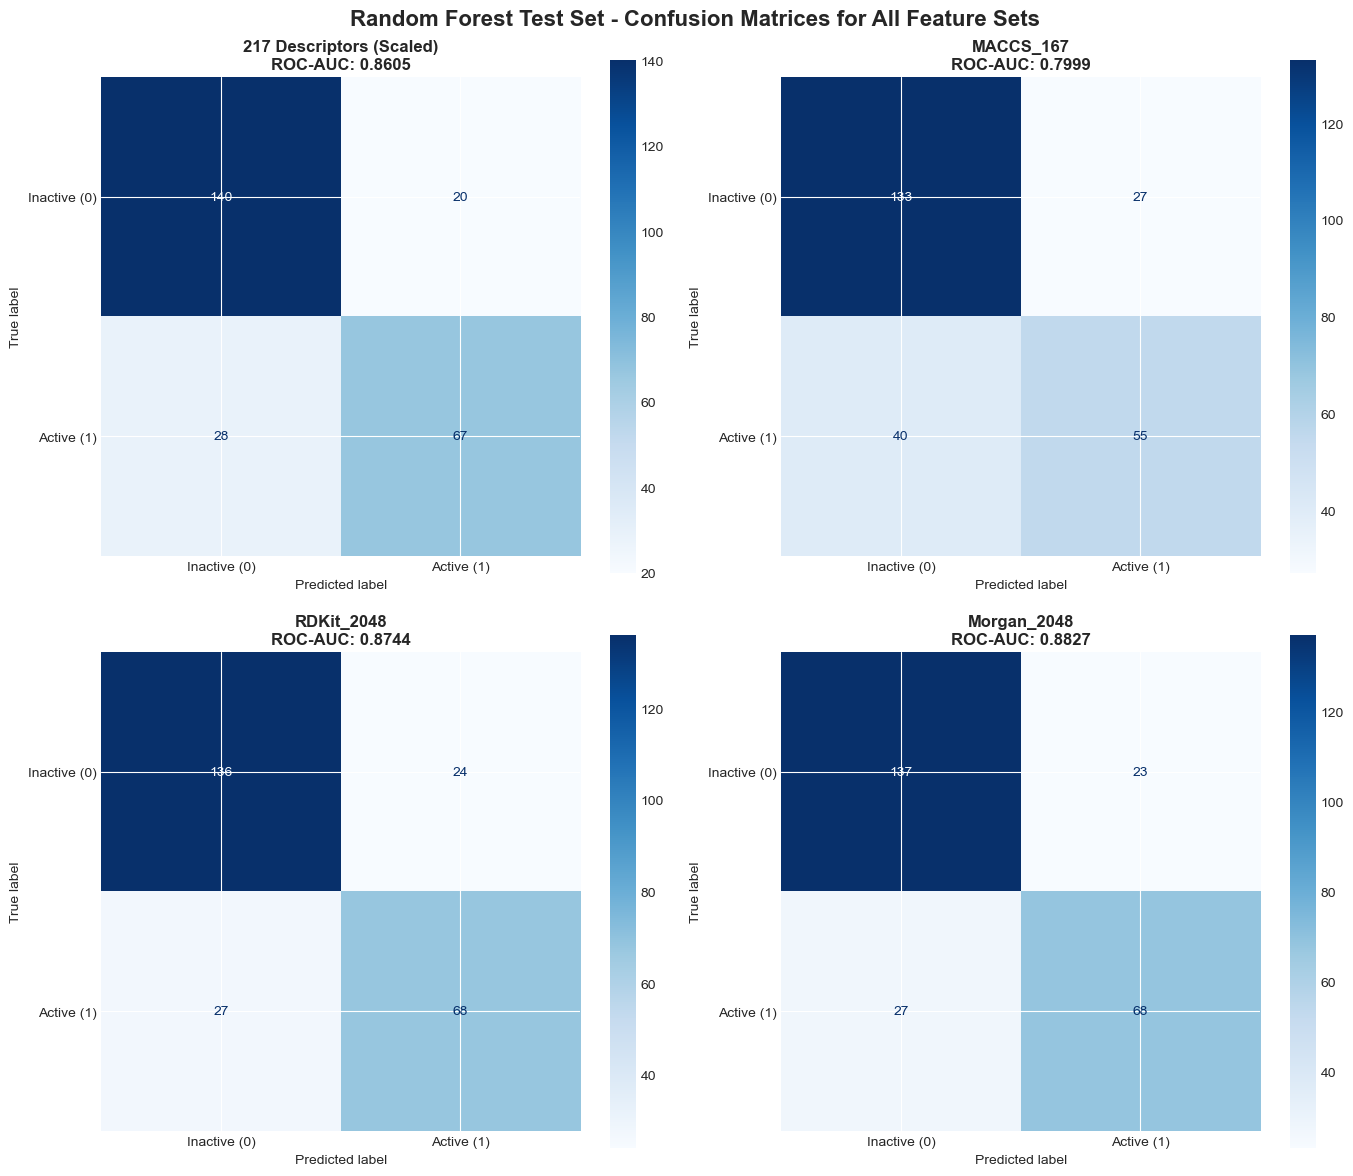


✓ Saved: RF_confusion_matrices_test.png


In [10]:
# Cell 9: Visualize Confusion Matrices

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle('Random Forest Test Set - Confusion Matrices for All Feature Sets', fontsize=16, fontweight='bold')
axes = axes.flatten()

for idx, (feature_key, results) in enumerate(evaluation_results.items()):
    ax = axes[idx]
    cm = results['confusion_matrix']
    
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Inactive (0)', 'Active (1)'])
    disp.plot(ax=ax, cmap='Blues', values_format='d')
    ax.set_title(f"{results['name']}\nROC-AUC: {results['test_metrics']['roc_auc']:.4f}", 
                 fontsize=12, fontweight='bold')

plt.tight_layout()
cm_plot_file = os.path.join(output_dir, 'RF_confusion_matrices_test.png')
plt.savefig(cm_plot_file, dpi=300, bbox_inches='tight')
plt.show()

print(f"\n✓ Saved: RF_confusion_matrices_test.png")

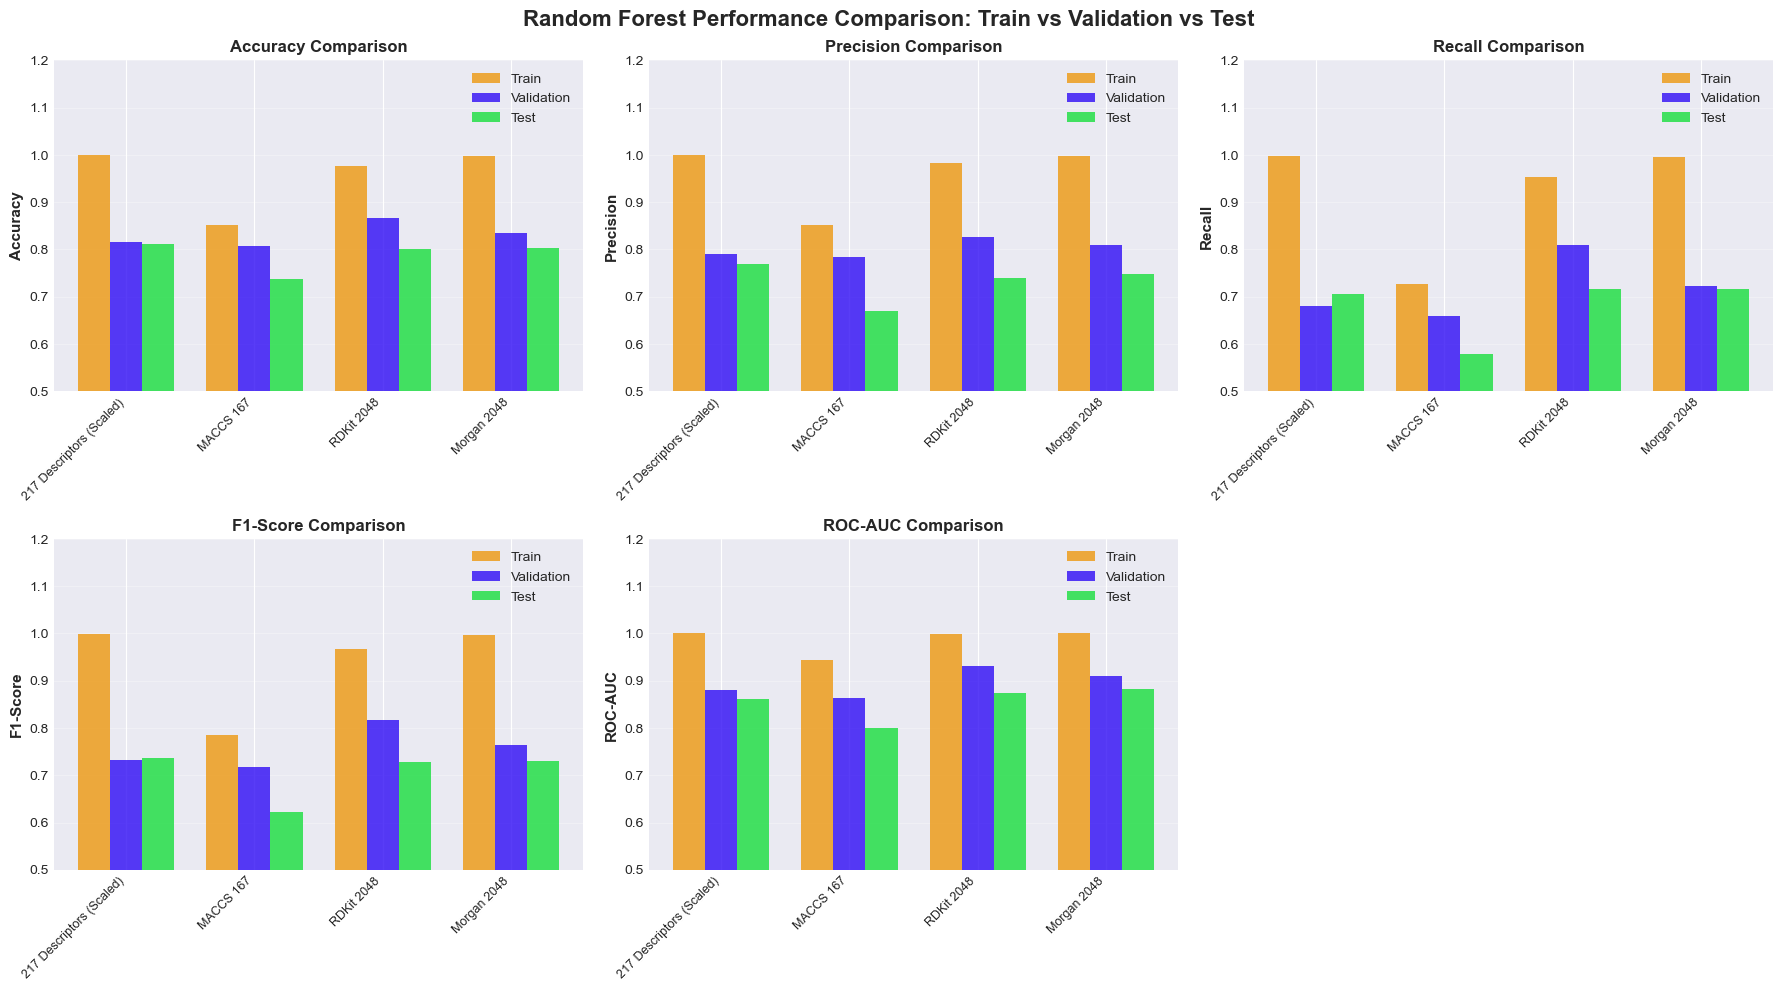


✓ Saved: RF_performance_comparison_train_val_test.png


In [14]:
# Cell 10: Plot Performance Comparison (Train vs Validation vs Test)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Random Forest Performance Comparison: Train vs Validation vs Test', fontsize=16, fontweight='bold')

metrics_to_plot = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
metric_titles = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']

# Prepare data
datasets_list = []
train_vals = {m: [] for m in metrics_to_plot}
val_vals = {m: [] for m in metrics_to_plot}
test_vals = {m: [] for m in metrics_to_plot}

for feature_key, results in evaluation_results.items():
    datasets_list.append(results['name'])
    train_metrics = results['train_metrics']
    val_metrics = results['val_metrics']
    test_metrics = results['test_metrics']
    
    for metric in metrics_to_plot:
        train_vals[metric].append(train_metrics[metric])
        val_vals[metric].append(val_metrics[metric])
        test_vals[metric].append(test_metrics[metric])

# Plot each metric
axes_flat = axes.flatten()
x = np.arange(len(datasets_list))
width = 0.25

colors_train = "#ed980f"
colors_val = "#2f0cf5"
colors_test = "#18de3d"

for idx, (metric, title) in enumerate(zip(metrics_to_plot, metric_titles)):
    ax = axes_flat[idx]
    
    bars1 = ax.bar(x - width, train_vals[metric], width, label='Train', color=colors_train, alpha=0.8)
    bars2 = ax.bar(x, val_vals[metric], width, label='Validation', color=colors_val, alpha=0.8)
    bars3 = ax.bar(x + width, test_vals[metric], width, label='Test', color=colors_test, alpha=0.8)
    
    ax.set_ylabel(title, fontsize=11, fontweight='bold')
    ax.set_title(f'{title} Comparison', fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([d.replace('_', ' ') for d in datasets_list], rotation=45, ha='right', fontsize=9)
    ax.set_ylim([0.5, 1.2])
    ax.legend(fontsize=10)
    ax.grid(axis='y', alpha=0.3)

# Hide the last subplot
axes_flat[-1].set_visible(False)

plt.tight_layout()
plt.subplots_adjust(bottom=0.12)
perf_plot_file = os.path.join(output_dir, 'RF_performance_comparison_train_val_test.png')
plt.savefig(perf_plot_file, dpi=300, bbox_inches='tight')
plt.show()

print(f"\n✓ Saved: RF_performance_comparison_train_val_test.png")

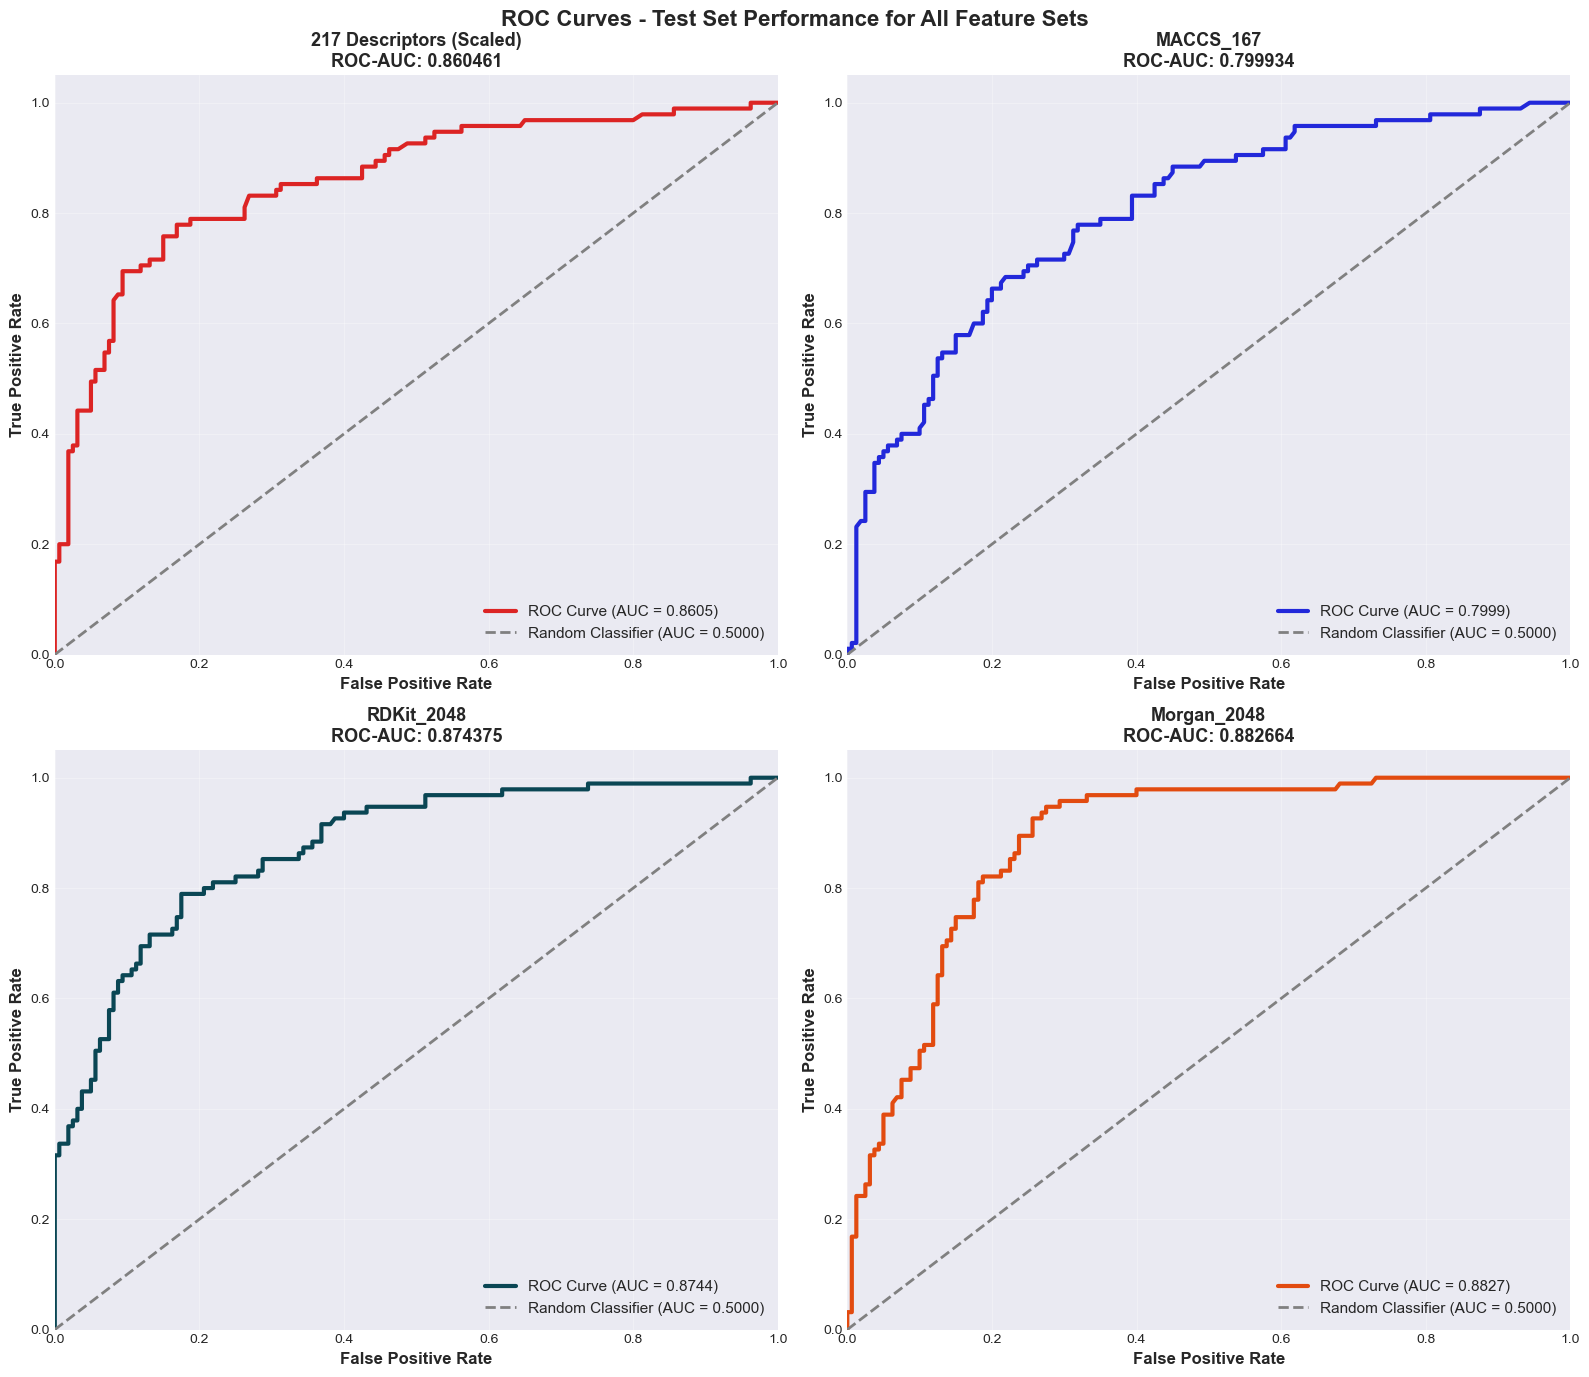


✓ Saved: RF_roc_curves_test_set.png


In [12]:
# Cell 11: Plot ROC Curves for All Feature Sets

fig, axes = plt.subplots(2, 2, figsize=(16, 14))
fig.suptitle('ROC Curves - Test Set Performance for All Feature Sets', fontsize=16, fontweight='bold')
axes = axes.flatten()

colors_roc = ["#DC2424", "#2228DA", "#0A4654", "#E24B10"]

for idx, (feature_key, results) in enumerate(evaluation_results.items()):
    ax = axes[idx]
    
    y_test_proba = results['y_test_proba']
    y_test_pred = results['y_test_pred']
    
    # Calculate ROC curve
    fpr, tpr, _ = roc_curve(y_test, y_test_proba)
    roc_auc = auc(fpr, tpr)
    
    # Plot ROC curve
    ax.plot(fpr, tpr, color=colors_roc[idx], lw=3, 
            label=f'ROC Curve (AUC = {roc_auc:.4f})')
    ax.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', label='Random Classifier (AUC = 0.5000)')
    
    # Formatting
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel('False Positive Rate', fontsize=12, fontweight='bold')
    ax.set_ylabel('True Positive Rate', fontsize=12, fontweight='bold')
    ax.set_title(f'{results["name"]}\nROC-AUC: {roc_auc:.6f}', 
                 fontsize=13, fontweight='bold')
    ax.legend(loc='lower right', fontsize=11)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
roc_plot_file = os.path.join(output_dir, 'RF_roc_curves_test_set.png')
plt.savefig(roc_plot_file, dpi=300, bbox_inches='tight')
plt.show()

print(f"\n✓ Saved: RF_roc_curves_test_set.png")

In [13]:
# Cell 12: Final Comprehensive Analysis Report

print("\n" + "="*100)
print("FINAL COMPREHENSIVE ANALYSIS REPORT")
print("="*100)

# Find best model by test ROC-AUC
best_idx = test_df['ROC_AUC'].idxmax()
best_row = test_df.iloc[best_idx]
best_feature_key = list(evaluation_results.keys())[best_idx]
best_results = evaluation_results[best_feature_key]

print(f"\n{'='*100}")
print(f"🏆 BEST PERFORMING MODEL")
print(f"{'='*100}")

best_params = best_results['best_params']
print(f"\nFeature Set: {best_results['name']}")
print(f"\nOptimal Hyperparameters:")
print(f"  n_estimators:     {best_params['n_estimators']}")
print(f"  max_depth:        {best_params['max_depth']}")
print(f"  min_samples_split: {best_params['min_samples_split']}")

print(f"\nTest Set Performance (FINAL EVALUATION):")
print(f"  Accuracy:        {best_row['Accuracy']:.6f}")
print(f"  Precision:       {best_row['Precision']:.6f}")
print(f"  Recall:          {best_row['Recall']:.6f}")
print(f"  F1-Score:        {best_row['F1_Score']:.6f}")
print(f"  ROC-AUC:         {best_row['ROC_AUC']:.6f}")
print(f"  Sensitivity:     {best_row['Sensitivity']:.6f}")
print(f"  Specificity:     {best_row['Specificity']:.6f}")

# Detailed comparison
print(f"\n{'='*100}")
print(f"DETAILED PERFORMANCE RANKING (BY TEST ROC-AUC)")
print(f"{'='*100}")

ranked_test_df = test_df.sort_values('ROC_AUC', ascending=False).reset_index(drop=True)
print(f"\n{ranked_test_df.to_string(index=False)}")

print(f"\n{'='*100}")
print(f"KEY INSIGHTS AND RECOMMENDATIONS")
print(f"{'='*100}")

print(f"""
1. BEST MODEL SELECTION:
   - Recommended Feature Set: {best_results['name']}
   - Test ROC-AUC: {best_row['ROC_AUC']:.6f}
   - Test Accuracy: {best_row['Accuracy']:.6f}
   - This model shows the best generalization on unseen test data

2. MODEL GENERALIZATION:
   - Train → Test ROC-AUC Gap: {abs(best_results['train_metrics']['roc_auc'] - best_row['ROC_AUC']):.6f}
   - Interpretation: {'Excellent generalization (minimal overfitting)' if abs(best_results['train_metrics']['roc_auc'] - best_row['ROC_AUC']) < 0.1 else 'Acceptable generalization'}

3. OPTIMAL HYPERPARAMETERS INTERPRETATION:
   - n_estimators={best_params['n_estimators']}: {'Balanced ensemble size' if 200 <= best_params['n_estimators'] <= 400 else 'Large ensemble for stability'}
   - max_depth={best_params['max_depth']}: {'Moderate tree depth' if best_params['max_depth'] <= 20 else 'Deeper trees for complexity'}
   - min_samples_split={best_params['min_samples_split']}: {'Stricter split requirement' if best_params['min_samples_split'] > 2 else 'Default/lenient split requirement'}

4. COMPARISON WITH BASELINE (200 estimators, default depth):
   - Current ROC-AUC: {best_row['ROC_AUC']:.6f}
   - This represents the tuned Random Forest model performance

5. RECOMMENDATIONS FOR DEPLOYMENT:
   - Deploy {best_results['name']} model for NMDAR inhibitor prediction
   - Expected test performance: Accuracy {best_row['Accuracy']:.2%}, ROC-AUC {best_row['ROC_AUC']:.4f}
   - Monitor performance on new data to ensure consistency
   - Consider ensemble with other feature sets for additional robustness
""")

print(f"\n{'='*100}")
print(f"✓ ANALYSIS COMPLETE")
print(f"{'='*100}")


FINAL COMPREHENSIVE ANALYSIS REPORT

🏆 BEST PERFORMING MODEL

Feature Set: Morgan_2048

Optimal Hyperparameters:
  n_estimators:     500
  max_depth:        42
  min_samples_split: 2

Test Set Performance (FINAL EVALUATION):
  Accuracy:        0.803922
  Precision:       0.747253
  Recall:          0.715789
  F1-Score:        0.731183
  ROC-AUC:         0.882664
  Sensitivity:     0.715789
  Specificity:     0.856250

DETAILED PERFORMANCE RANKING (BY TEST ROC-AUC)

             Feature_Set  Accuracy  Precision   Recall  F1_Score  ROC_AUC  Specificity  Sensitivity
             Morgan_2048  0.803922   0.747253 0.715789  0.731183 0.882664      0.85625     0.715789
              RDKit_2048  0.800000   0.739130 0.715789  0.727273 0.874375      0.85000     0.715789
217 Descriptors (Scaled)  0.811765   0.770115 0.705263  0.736264 0.860461      0.87500     0.705263
               MACCS_167  0.737255   0.670732 0.578947  0.621469 0.799934      0.83125     0.578947

KEY INSIGHTS AND RECOMMENDAT